# Comet outgassing: the rocket effect on 10P/Tempel 2

**The question.** Near perihelion a comet's ice sublimates and the escaping gas pushes back on the
nucleus. That *non-gravitational* acceleration is thousands of times larger than an asteroid's
Yarkovsky push: an orbit computed from gravity alone drifts away from the comet within a single
return. How big is the push on 10P/Tempel 2, a Jupiter-family comet with a 5.4-year period and
one of the larger known nuclei (roughly 16 by 8 km), which way does it point, and does PyRoOrb
find the same answer as JPL without being told what to look for?

PyRoOrb uses the standard Marsden et al. (1973) model: radial, transverse and normal accelerations
$A_1, A_2, A_3$ (au/day²) scaled by the water-sublimation curve $g(r)$, which switches the force on
inside ~3 au. For a comet designation, every fit tries gravity-only, then $A_1$, $A_1A_2$ and
$A_1A_2A_3$, and keeps the richest model the data justify.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## 1. Fetch, and keep the span JPL uses

Tempel 2 has been observed since 1873, but outgassing changes slowly from return to return, so a
single set of constant $A$'s is fitted over a limited span. JPL's current solution starts in
March 2003; we keep the same span: five returns, 2005 to 2026.

In [2]:
from astropy.time import Time

everything = pyroorb.fetch_observations("10P")
obs = everything.select(start="2003-03-01")
print(f"{len(everything)} observations in the archive, {len(obs)} since 2003-03")

8305 observations in the archive, 7347 since 2003-03


## 2. The automatic fit

In [3]:
fit = pyroorb.fit_orbit(obs, designation="10P")
print(f"{fit.n_observations()}/{fit.n_total_observations()} observations kept, rms {fit.rms_residual():.3f}\", "
      f"model: {fit.nongrav_model}")
for k, v in fit.nongrav_params.items():
    lo, hi = fit.rational_nongrav_intervals()[k]
    print(f"  {k} = {v:+.3e}  (-{lo:.1e} / +{hi:.1e}) au/day^2   [{abs(v) / lo:.0f} sigma]")

disc = fit.nongrav_discovery["comet"]       # the model ladder it climbed (internal API, may change)
base = disc["compare_base"]
print(f"\n{'model':8s} {'rms':>6s} {'chi2':>9s} {'dBIC':>7s}  coefficients      (N = {base['N']} residuals)")
print(f"{'gravity':8s} {disc['rms0']:6.3f} {base['chi2_0']:9.1f}")
prev, k_prev = base["chi2_0"], 6
for name, m in disc["compare"].items():
    k = 6 + len(m["params"])
    dbic = (prev - m["chi2"]) - (k - k_prev) * np.log(base["N"])    # gain over the previous rung
    print(f"{name:8s} {m['rms']:6.3f} {m['chi2']:9.1f} {dbic:7.1f}  "
          + ", ".join(f"{k}={v:.2e}" for k, v in m["params"].items()))
    prev, k_prev = m["chi2"], k

6952/7347 observations kept, rms 0.576", model: comet2


  A1 = +2.826e-10  (-6.9e-12 / +6.9e-12) au/day^2   [41 sigma]
  A2 = +8.263e-12  (-2.0e-13 / +2.0e-13) au/day^2   [42 sigma]

model       rms      chi2    dBIC  coefficients      (N = 720 residuals)
gravity   2.481    5293.3
comet1    2.468    5135.6   151.1  A1=1.55e-10
comet2    2.444    4867.0   262.0  A1=2.49e-10, A2=7.83e-12
comet3    2.445    4866.9    -6.4  A1=2.49e-10, A2=7.82e-12, A3=1.50e-11


The ladder climbs two rungs and stops. Adding $A_1$ (radial) and then $A_2$ (transverse) each
lowers the weighted χ² by far more than the BIC penalty for a parameter; the third rung, an
out-of-plane $A_3$, gains almost nothing and is refused. That is the model JPL fits for this comet.

The push is mostly **radial** (outward, as sublimation from the sunlit side must be), with a
small **transverse** component along the motion, $A_2 > 0$: the comet gains a little orbital
energy each return, so its period lengthens.

## 3. What gravity alone does: it throws observations away

A gravity-only fit (`nongrav="none"`) can still reach a small rms. It gets there by **rejecting**
the observations it cannot fit, and those pile up around the perihelia, where the comet is active.
The plot shows every observation's residual under each orbit; perihelion passages are marked.

gravity only: 6502/7347 kept, rms 0.640"
outgassing  : 6952/7347 kept, rms 0.576"


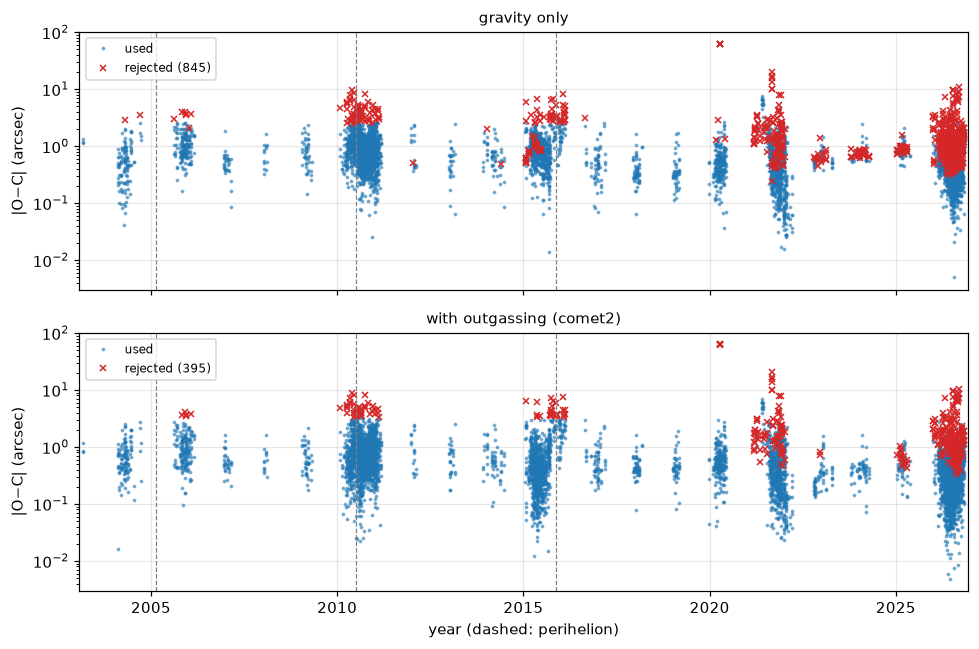

In [4]:
grav = pyroorb.fit_orbit(obs, designation="10P", nongrav="none")      # gravity only
print(f"gravity only: {grav.n_observations()}/{grav.n_total_observations()} kept, rms {grav.rms_residual():.3f}\"")
print(f"outgassing  : {fit.n_observations()}/{fit.n_total_observations()} kept, rms {fit.rms_residual():.3f}\"")

tp, period = fit.elements()["Tp"], fit.elements()["P"] * 365.25
perihelia = [tp + k * period for k in range(-4, 3)]
yr = lambda jd: Time(jd, format="jd").decimalyear

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, sharey=True)
for ax, f, title in ((axes[0], grav, "gravity only"), (axes[1], fit, f"with outgassing ({fit.nongrav_model})")):
    res = f.residuals()
    t = yr(np.array([r["jd_utc"] for r in res]))
    tot = np.array([np.hypot(r["d_ra_arcsec"], r["d_dec_arcsec"]) for r in res])
    inc = np.array([r["included"] for r in res])
    ax.semilogy(t[inc], tot[inc], ".", ms=3, alpha=0.5, label="used")
    ax.semilogy(t[~inc], tot[~inc], "x", ms=4, color="C3", label=f"rejected ({(~inc).sum()})")
    for p in perihelia:
        ax.axvline(yr(p), color="0.5", ls="--", lw=0.8)
    ax.set_title(title, fontsize=10); ax.set_ylabel("|O−C| (arcsec)"); ax.legend(fontsize=8, loc="upper left")
axes[1].set_xlim(yr(min(r["jd_utc"] for r in res)) - 0.1, yr(max(r["jd_utc"] for r in res)) + 0.1)
axes[1].set_xlabel("year (dashed: perihelion)"); plt.tight_layout(); plt.show()

## 4. Compare with JPL

JPL's current solution for Tempel 2 fits $A_1$ and $A_2$, the same two parameters the ladder
chose, on the same span.

JPL orbit K265/60 data 2003-03-07 to 2026-10-29 model: A1, A2
JPL                           A1 = 2.562e-10 ± 1.1e-11  A2 = 8.335e-12 ± 2.8e-13
PyRoOrb automatic (comet2)    A1 = 2.826e-10 ± 6.9e-12  A2 = 8.263e-12 ± 2.0e-13
A1: PyRoOrb - JPL = +2.4 JPL sigma
A2: PyRoOrb - JPL = -0.3 JPL sigma


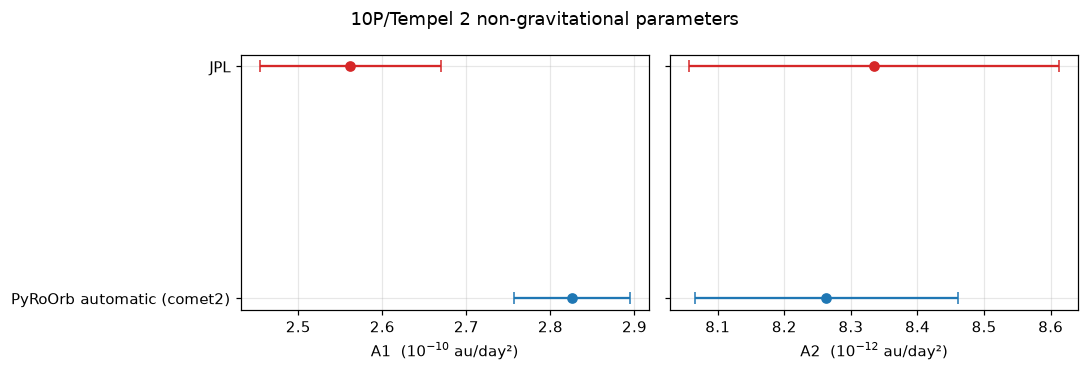

In [5]:
import json, urllib.request

sbdb = json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb.api?sstr=10P"))
jpl = {p["name"]: (float(p["value"]), float(p["sigma"])) for p in sbdb["orbit"]["model_pars"]}
print("JPL orbit", sbdb["orbit"]["orbit_id"], "data", sbdb["orbit"]["first_obs"], "to", sbdb["orbit"]["last_obs"],
      "model:", ", ".join(k for k in ("A1", "A2", "A3", "DT") if k in jpl))

sol = {"JPL": {k: jpl[k] for k in ("A1", "A2")},
       f"PyRoOrb automatic ({fit.nongrav_model})": {k: (v, fit.rational_nongrav_intervals()[k][0])
                                                    for k, v in fit.nongrav_params.items()}}
for name, d in sol.items():
    print(f"{name:30s}" + "  ".join(f"{k} = {v:.3e} ± {s:.1e}" for k, (v, s) in d.items()))
for k in ("A1", "A2"):
    print(f"{k}: PyRoOrb - JPL = {(fit.nongrav_params[k] - jpl[k][0]) / jpl[k][1]:+.1f} JPL sigma")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, k, scale in ((axes[0], "A1", 1e-10), (axes[1], "A2", 1e-12)):
    for j, (name, d) in enumerate(sol.items()):
        ax.errorbar(d[k][0] / scale, j, xerr=d[k][1] / scale, fmt="o", capsize=4, color=f"C{3 if j == 0 else 0}")
    ax.set_yticks(range(len(sol)), list(sol) if k == "A1" else [""] * len(sol)); ax.invert_yaxis()
    ax.set_xlabel(f"{k}  ($10^{{{int(np.log10(scale))}}}$ au/day²)")
plt.suptitle("10P/Tempel 2 non-gravitational parameters"); plt.tight_layout(); plt.show()

## 5. How far does the push move the comet?

`pyroorb.propagate(fit, times, nongrav=False)` integrates the same fitted state without its
outgassing force. The gap between the two trajectories is what a gravity-only prediction from
this orbit would miss.

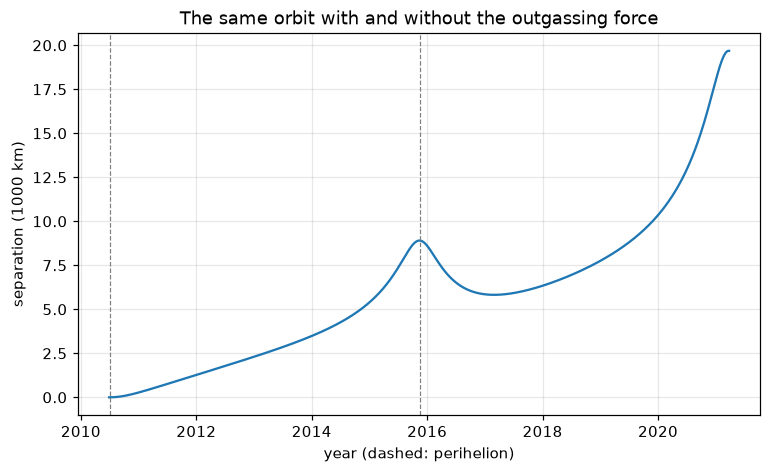

one return after the epoch (2015-11-11): the two trajectories are 8,907 km apart, 0.1 hours of the comet's motion
two returns: 19,684 km, 0.2 hours


In [6]:
AU_KM = 1.495978707e8
epoch = Time(fit.epoch_jd(), format="jd", scale="tdb")
t = Time(fit.epoch_jd() + np.arange(0, 2 * period, 2.0), format="jd", scale="tdb")
with_push = pyroorb.propagate(fit, t)
without = pyroorb.propagate(fit, t, nongrav=False)
gap = np.linalg.norm(with_push[:, :3] - without[:, :3], axis=1) * AU_KM
speed = np.linalg.norm(with_push[:, 3:], axis=1) * AU_KM / 86400                # km/s

plt.plot(t.decimalyear, gap / 1e3)
for p in perihelia:
    if t.jd[0] <= p <= t.jd[-1]:
        plt.axvline(yr(p), color="0.5", ls="--", lw=0.8)
plt.xlabel("year (dashed: perihelion)"); plt.ylabel("separation (1000 km)")
plt.title("The same orbit with and without the outgassing force"); plt.show()
k1 = np.argmin(abs(t.jd - (fit.epoch_jd() + period)))
print(f"one return after the epoch ({t[k1].iso[:10]}): the two trajectories are {gap[k1]:,.0f} km apart,"
      f" {gap[k1] / speed[k1] / 3600:.1f} hours of the comet's motion")
print(f"two returns: {gap[-1]:,.0f} km, {gap[-1] / speed[-1] / 3600:.1f} hours")

## Takeaways

* The automatic model selection lands on JPL's model, radial plus transverse, and refuses the
  third component on its own: the ladder is a statistical test, and here it reads the data the
  way the reference solution does.
* The transverse coefficient, the one that changes the period, agrees with JPL's to a fraction
  of its σ; the radial one, which the astrometry constrains more weakly, is within a few σ.
* The push is real and large: left out, the same orbit drifts by about 9,000 km in one return
  and 20,000 km in two, six to twelve minutes of the comet's motion, which from Earth is a dozen
  arcseconds or more, twenty times the astrometric noise. That is why every comet orbit needs it.

**Caveats.** The constant-$A$ Marsden model is an approximation; real outgassing varies between
returns and is asymmetric about perihelion. On a comet whose data favour such asymmetry the
ladder can climb one rung too far (the normal component, $A_3$, absorbing what the symmetric law
cannot represent); Tempel 2 is a case where it does not.